# Ionic Conductivity ML — Data Foundation and Neural-Network Design

## Project goal

Develop a validated neural network that predicts lithium-ion conductivity from composition, crystal structure, temperature, and documented measurement conditions. The ML phase will also identify stable, physically meaningful variables and representative materials for later DFT, molecular-dynamics, and phase-field studies; no simulations are performed during this phase.

### Current outcome

This notebook defines the target and validation contract, specifies the neural-network architecture, and performs a literature-backed ingestion and quality audit of the OBELiX experimental solid-electrolyte dataset. The Materials Project setup is retained for later structure matching and screening, while all conductivity labels retain their original source and quality flags.


## 1. Modeling decisions

| Decision | Current specification |
|---|---|
| Mobile ion | Li$^+$ only for model v1 |
| Working material scope | Inorganic solid-state lithium-ion conductors |
| Predicted property | Ionic conductivity, excluding electronic and total conductivity |
| Canonical unit | S/cm |
| Model target | $\log_{10}(\sigma_{\mathrm{ion}}/\mathrm{S\,cm^{-1}})$ |
| Temperature strategy | Phase 1 predicts nominal room-temperature conductivity; a temperature-conditioned Arrhenius model requires multi-temperature labels |
| Unit of observation | One conductivity value for one resolved material phase at one documented condition |
| Primary benchmark | Official OBELiX train/test split, which groups common compositions and publications |
| Cross-validation group | Connected records sharing a material identity or source DOI |
| Strong generalization test | Complete chemical systems excluded from training as a secondary stress test |
| Intended use | Dataset analysis, prediction, uncertainty estimation, and variable selection—not autonomous materials decisions |

**Scope rule:** polymers, liquids, composites, and non-lithium conductors remain outside model v1. Censored conductivity values are preserved for auditing but are not treated as exact regression labels.


In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/battery_ml_matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
RAW_MP_PATH = ROOT / "data/raw/mp_li_insertion_electrodes.json"
MP_FEATURE_PATH = ROOT / "data/processed/li_insertion_electrodes_features.csv"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Figure system adapted from the supplied report and the official UIUC palette.
ILLINI_BLUE = "#13294B"
ILLINI_ORANGE = "#FF5F05"
ILLINI_STORM = "#707372"
ILLINI_STORM_LIGHT = "#C6C7C6"


def apply_report_style():
    plt.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "grid.color": ILLINI_STORM_LIGHT,
        "grid.linewidth": 0.7,
        "grid.alpha": 0.85,
        "lines.linewidth": 1.5,
    })


def finish_axis(axis, grid_axis="y"):
    axis.grid(True, axis=grid_axis)
    axis.set_axisbelow(True)
    axis.tick_params(direction="out", length=4, width=0.9)


def save_report_figure(figure, filename):
    output = FIGURE_DIR / filename
    figure.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved figure:", output)


apply_report_style()

# Keep the existing MP setup, but make both local caches optional so this
# Day 1 notebook remains runnable when distributed with only its deliverables.
raw_cache_available = RAW_MP_PATH.exists()
feature_cache_available = MP_FEATURE_PATH.exists()
if raw_cache_available:
    mp_records = pd.DataFrame(json.loads(RAW_MP_PATH.read_text(encoding="utf-8")))
elif feature_cache_available:
    mp_records = pd.read_csv(MP_FEATURE_PATH)
else:
    mp_records = pd.DataFrame()

conductivity_fields = [
    column for column in mp_records.columns
    if "conduct" in column.lower() or "sigma" in column.lower()
]
unique_chemsys = (
    mp_records["chemsys"].nunique()
    if "chemsys" in mp_records.columns
    else 0
)

current_data_audit = pd.Series(
    {
        "raw_MP_cache_available": raw_cache_available,
        "processed_MP_cache_available": feature_cache_available,
        "available_MP_records": len(mp_records),
        "unique_MP_chemical_systems": unique_chemsys,
        "conductivity_fields_in_current_MP_cache": len(conductivity_fields),
    },
    name="value",
)
display(current_data_audit.to_frame())
print("Matching conductivity fields:", conductivity_fields or "none")
print(
    "Decision: MP supplies candidate structures and descriptors; "
    "a separate ionic-conductivity label table is required."
)


,value
raw_MP_cache_available,True
processed_MP_cache_available,True
available_MP_records,2774
unique_MP_chemical_systems,670
conductivity_fields_in_current_MP_cache,0


Matching conductivity fields: none
Decision: MP supplies candidate structures and descriptors; a separate ionic-conductivity label table is required.


## 2. Target definition

Conductivity usually spans several orders of magnitude, so the regression target is

$$
y_i=\log_{10}\!\left(\frac{\sigma_{\mathrm{ion},i}}{1\ \mathrm{S\,cm^{-1}}}\right).
$$

The prediction is converted back to physical units using

$$
\widehat{\sigma}_{\mathrm{ion},i}=10^{\hat y_i}\ \mathrm{S\,cm^{-1}}.
$$

An MAE of $m$ in log space corresponds approximately to a multiplicative error factor of $10^m$. For example, MAE $=0.5$ means a typical error of roughly a factor of 3.2.

Temperature is retained explicitly:

$$
\hat y=f(\text{composition},\text{structure},T,\text{documented conditions}).
$$

This avoids treating measurements made at different temperatures as if they represented the same target. Predictions will later be compared at 298.15 K, but measured values will not be extrapolated to room temperature unless a documented Arrhenius fit is available.

In [2]:
TARGET_COLUMN = "log10_sigma_S_cm"
REFERENCE_TEMPERATURE_K = 298.15
MOBILE_ION = "Li"
MATERIAL_SCOPE = "inorganic solid-state lithium-ion conductor"

DATA_SCHEMA = [
    ("record_id", "string", "Unique source-record identifier", True),
    ("material_key", "string", "Canonical material/phase identifier", True),
    ("mp_id", "string", "Materials Project ID when a confident match exists", False),
    ("formula", "string", "Reported chemical formula", True),
    ("chemsys", "string", "Hyphen-separated chemical system", True),
    ("structure_id", "string", "Structure or polymorph identifier", False),
    ("phase", "string", "Reported phase or space group", False),
    ("mobile_ion", "string", "Li for model v1", True),
    ("material_class", "string", "Electrolyte/material family", True),
    ("conductivity_value", "float", "Positive value in the reported unit", True),
    ("conductivity_unit", "string", "Unit before normalization", True),
    ("temperature_K", "float", "Measurement or simulation temperature in kelvin", True),
    ("conductivity_type", "string", "Must explicitly identify ionic conductivity", True),
    ("label_origin", "string", "experimental, MD, or other computed source", True),
    ("measurement_method", "string", "Impedance, MD, or other method", False),
    ("uncertainty", "float", "Reported uncertainty when available", False),
    ("reference", "string", "DOI, database record, or source citation", True),
    ("notes", "string", "Processing, density, grain, or quality notes", False),
]

schema_df = pd.DataFrame(
    DATA_SCHEMA,
    columns=["column", "dtype", "definition", "required"],
)
display(schema_df)

,column,dtype,definition,required
0,record_id,string,Unique source-record identifier,True
1,material_key,string,Canonical material/phase identifier,True
2,mp_id,string,Materials Project ID when a confident match ex...,False
3,formula,string,Reported chemical formula,True
4,chemsys,string,Hyphen-separated chemical system,True
5,structure_id,string,Structure or polymorph identifier,False
6,phase,string,Reported phase or space group,False
7,mobile_ion,string,Li for model v1,True
8,material_class,string,Electrolyte/material family,True
9,conductivity_value,float,Positive value in the reported unit,True


## 3. Neural-network model: staged crystal graph learning

### Model in battery language

The long-term algorithm is a **Physics-Informed Arrhenius Crystal Graph Neural Network (PI-ACGNN)**. It reads a periodic crystal structure, learns which local atomic environments support lithium transport, and predicts conductivity with uncertainty. A pretrained encoder such as CHGNet is the initial transfer-learning choice; M3GNet and ALIGNN remain alternatives if they fit the final data more reliably.

Training is staged to match the available evidence. OBELiX supplies room-temperature labels, so Phase 1 trains a composition-only multilayer perceptron (MLP), an unconstrained crystal graph network, and a transfer-learned room-temperature conductivity head. The Arrhenius heads are activated only after a multi-temperature dataset makes activation energy and prefactor identifiable.

### What is a crystal graph layer?

A crystal graph is $\mathcal G=(\mathcal V,\mathcal E)$: each node $v\in\mathcal V$ is an atom and each periodic edge $(u,v)\in\mathcal E$ is a neighboring atomic pair described by distance and, where available, angle information. At layer $\ell$, the network collects messages from each atom's neighbors and updates its hidden state:

$$
\mathbf m_v^{(\ell)}=\sum_{u\in\mathcal N(v)}
\phi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf h_u^{(\ell)},\mathbf e_{uv}\right),
\qquad
\mathbf h_v^{(\ell+1)}=\psi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf m_v^{(\ell)}\right).
$$

Here, $\phi_\ell$ and $\psi_\ell$ are small trainable neural networks, $\mathbf e_{uv}$ describes local geometry, and $\mathcal N(v)$ is the periodic neighbor list. Pooling the final atom states gives one material vector,

$$
\mathbf h_{\mathrm{crystal}}=\operatorname{Pool}\!\left(\{\mathbf h_v^{(L)}\}_{v\in\mathcal V}\right).
$$

### Physics-informed prediction head

Once multi-temperature labels are available, two heads estimate a positive activation energy and a conductivity prefactor:

$$
\widehat{E}_a=\operatorname{softplus}\!\left(g_E(\mathbf h_{\mathrm{crystal}})\right)>0,
\qquad
\widehat{\log_{10}\sigma_0}=g_0(\mathbf h_{\mathrm{crystal}}).
$$

The physics layer imposes the Arrhenius relation

$$
\widehat{\log_{10}\sigma(T)}=
\widehat{\log_{10}\sigma_0}
-\frac{\widehat{E}_a}{k_{\mathrm B}T\ln 10}.
$$

If validation reveals systematic non-Arrhenius behavior, a small correction $r_\theta(\mathbf h,T)$ may be added only when it improves unseen-material performance. The full loss is

$$
\mathcal L=\mathcal L_{\mathrm{NLL}}
+\lambda_r\lVert r_\theta\rVert_2^2
+\lambda_T\sum_i\max\!\left(0,-\frac{\partial \hat y_i}{\partial T}\right)^2,
$$

where $\mathcal L_{\mathrm{NLL}}$ is a heteroscedastic Gaussian negative log likelihood. A multi-seed deep ensemble estimates model uncertainty.

### Literature-backed training order

1. Audit the label distribution, censoring, repeated measurements, structure availability, and split integrity.
2. Train a composition-only MLP on the official leakage-controlled OBELiX split.
3. Freeze a pretrained crystal encoder and train a room-temperature conductivity and uncertainty head on structure-matched records.
4. Compare the MLP, unconstrained GNN, and transfer-learned GNN using identical test records where possible.
5. Activate the Arrhenius head only after adding repeated temperatures for the same materials.

This caution is important: the OBELiX paper reports that geometric GNNs overfit its small structure subset, while a simpler model performed better on the held-out test set. Transfer learning, strict grouping, and uncertainty calibration are therefore requirements rather than optional refinements.

Primary references: [OBELiX](https://doi.org/10.1039/d5dd00441a), [CHGNet](https://doi.org/10.1038/s42256-023-00716-3), [M3GNet](https://doi.org/10.1038/s43588-022-00349-3), and [ALIGNN](https://doi.org/10.1038/s41524-021-00650-1).


In [3]:
ADVANCED_MODEL_SPEC = pd.Series(
    {
        "long_term_model": "Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)",
        "current_trainable_model": "room-temperature transfer-learned crystal GNN",
        "structure_encoder": "pretrained CHGNet; evaluate M3GNet/ALIGNN if needed",
        "current_neural_baseline": "composition MLP",
        "uncertainty": "heteroscedastic head plus multi-seed deep ensemble",
        "validation": "official OBELiX split plus linked material/DOI groups",
        "identifiability_gate": "do not fit Ea and sigma0 separately from room-temperature-only labels",
        "selection_rule": "adopt added complexity only if held-out accuracy and calibration improve",
    },
    name="neural-network decision",
)
display(ADVANCED_MODEL_SPEC.to_frame())


,neural-network decision
long_term_model,Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)
current_trainable_model,room-temperature transfer-learned crystal GNN
structure_encoder,pretrained CHGNet; evaluate M3GNet/ALIGNN if n...
current_neural_baseline,composition MLP
uncertainty,heteroscedastic head plus multi-seed deep ense...
validation,official OBELiX split plus linked material/DOI...
identifiability_gate,do not fit Ea and sigma0 separately from room-...
selection_rule,adopt added complexity only if held-out accura...


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_01_physics_informed_conductivity_model.png


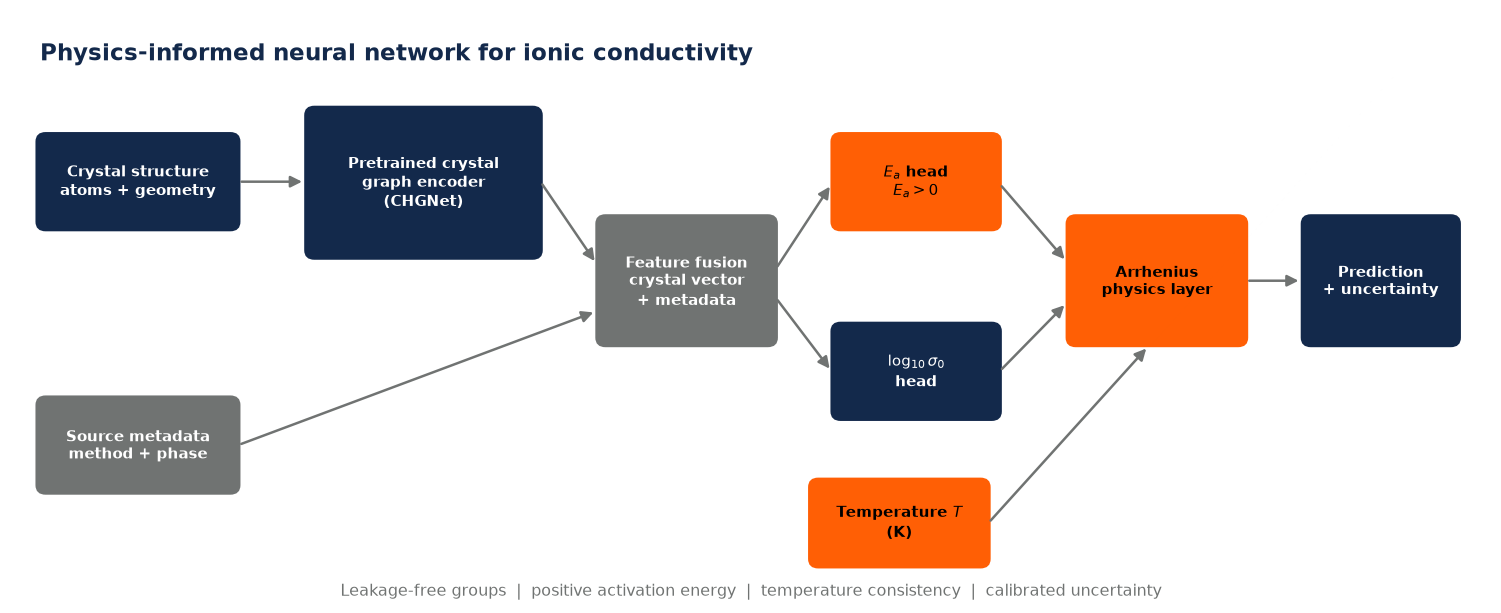

In [4]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


def architecture_box(axis, xy, width, height, text, facecolor, textcolor="white"):
    box = FancyBboxPatch(
        xy, width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4, edgecolor=facecolor, facecolor=facecolor,
    )
    axis.add_patch(box)
    axis.text(
        xy[0] + width / 2, xy[1] + height / 2, text,
        ha="center", va="center", color=textcolor,
        fontsize=9.2, fontweight="bold", linespacing=1.22,
    )


def architecture_arrow(axis, start, end):
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color=ILLINI_STORM,
        connectionstyle="arc3,rad=0.0",
    ))


fig, axis = plt.subplots(figsize=(12.4, 5.0), constrained_layout=True)
axis.set_xlim(0, 13.2)
axis.set_ylim(0, 5.6)
axis.axis("off")

axis.text(
    0.25, 5.3, "Physics-informed neural network for ionic conductivity",
    color=ILLINI_BLUE, fontsize=14, fontweight="bold", va="top",
)

architecture_box(axis, (0.25, 3.55), 1.75, 0.86, "Crystal structure\natoms + geometry", ILLINI_BLUE)
architecture_box(axis, (0.25, 1.05), 1.75, 0.86, "Source metadata\nmethod + phase", ILLINI_STORM)
architecture_box(axis, (7.15, 0.35), 1.55, 0.78, "Temperature $T$\n(K)", ILLINI_ORANGE, "black")

architecture_box(axis, (2.65, 3.28), 2.05, 1.38, "Pretrained crystal\ngraph encoder\n(CHGNet)", ILLINI_BLUE)
architecture_box(axis, (5.25, 2.45), 1.55, 1.18, "Feature fusion\ncrystal vector\n+ metadata", ILLINI_STORM)
architecture_box(axis, (7.35, 3.55), 1.45, 0.86, "$E_a$ head\n$E_a>0$", ILLINI_ORANGE, "black")
architecture_box(axis, (7.35, 1.75), 1.45, 0.86, "$\\log_{10}\\sigma_0$\nhead", ILLINI_BLUE)
architecture_box(axis, (9.45, 2.45), 1.55, 1.18, "Arrhenius\nphysics layer", ILLINI_ORANGE, "black")
architecture_box(axis, (11.55, 2.45), 1.35, 1.18, "Prediction\n+ uncertainty", ILLINI_BLUE)

architecture_arrow(axis, (2.02, 3.98), (2.62, 3.98))
architecture_arrow(axis, (4.72, 3.98), (5.22, 3.20))
architecture_arrow(axis, (2.02, 1.48), (5.22, 2.75))
architecture_arrow(axis, (6.82, 3.15), (7.32, 3.96))
architecture_arrow(axis, (6.82, 2.88), (7.32, 2.18))
architecture_arrow(axis, (8.82, 3.96), (9.42, 3.22))
architecture_arrow(axis, (8.82, 2.18), (9.42, 2.83))
architecture_arrow(axis, (8.72, 0.74), (10.15, 2.42))
architecture_arrow(axis, (11.02, 3.04), (11.52, 3.04))

axis.text(
    6.6, 0.05,
    "Leakage-free groups  |  positive activation energy  |  "
    "temperature consistency  |  calibrated uncertainty",
    color=ILLINI_STORM, fontsize=9.3, ha="center",
)

save_report_figure(fig, "figure_01_physics_informed_conductivity_model.png")
plt.show()


**Figure 1.** Long-term PI-ACGNN workflow. The crystal graph encoder learns a structural representation, which is fused with documented non-outcome metadata. Separate neural heads estimate a positive activation energy and conductivity prefactor; the Arrhenius layer combines them with temperature to predict log conductivity, while the ensemble reports uncertainty. The room-temperature conductivity head can be trained first, but the Arrhenius heads remain gated until multi-temperature measurements make their latent parameters identifiable.


## 4. Label normalization and acceptance checks

Every source value must retain its original value and unit. The normalization step creates new canonical columns rather than overwriting source data.

Accepted conductivity units in the first ingestion pass are S/cm, mS/cm, µS/cm, S/m, and mS/m. Resistivity values must be identified and converted separately using $\sigma=1/\rho$; they must never be passed to the conductivity converter as if they were conductivity.

In [5]:
UNIT_TO_S_CM = {
    "S/cm": 1.0,
    "mS/cm": 1e-3,
    "uS/cm": 1e-6,
    "µS/cm": 1e-6,
    "S/m": 1e-2,
    "mS/m": 1e-5,
}

REQUIRED_COLUMNS = [row[0] for row in DATA_SCHEMA if row[3]]


def conductivity_to_s_cm(value: float, unit: str) -> float:
    # Convert a positive conductivity value to S/cm.
    if unit not in UNIT_TO_S_CM:
        raise ValueError(f"Unsupported conductivity unit: {unit!r}")
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError("Conductivity must be finite and strictly positive.")
    return value * UNIT_TO_S_CM[unit]


def material_group_key(row: pd.Series) -> str:
    # Keep polymorphs and repeated temperatures together during validation.
    for column in ("material_key", "mp_id", "structure_id"):
        value = row.get(column)
        if pd.notna(value) and str(value).strip():
            return str(value).strip()
    return f"{row.get('formula', 'unknown')}|{row.get('phase', 'unknown')}"


def prepare_conductivity_labels(frame: pd.DataFrame) -> pd.DataFrame:
    # Validate source labels and create canonical ML columns.
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise KeyError(f"Missing required source columns: {missing}")

    prepared = frame.copy()
    prepared["sigma_S_cm"] = [
        conductivity_to_s_cm(value, unit)
        for value, unit in zip(
            prepared["conductivity_value"],
            prepared["conductivity_unit"],
        )
    ]
    prepared["temperature_K"] = pd.to_numeric(
        prepared["temperature_K"], errors="raise"
    )
    if not prepared["temperature_K"].between(100, 2000).all():
        raise ValueError("Review temperatures outside the broad 100–2000 K audit range.")
    if not prepared["mobile_ion"].eq(MOBILE_ION).all():
        raise ValueError("Model v1 accepts Li-ion records only.")
    if not prepared["conductivity_type"].str.lower().eq("ionic").all():
        raise ValueError("Non-ionic or ambiguous conductivity records must be separated.")

    prepared[TARGET_COLUMN] = np.log10(prepared["sigma_S_cm"])
    prepared["group_material"] = prepared.apply(material_group_key, axis=1)
    return prepared


intake_template = pd.DataFrame(columns=[row[0] for row in DATA_SCHEMA])
INTAKE_TEMPLATE_PATH = ROOT / "data/processed/ionic_conductivity_intake_template.csv"
INTAKE_TEMPLATE_PATH.parent.mkdir(parents=True, exist_ok=True)
intake_template.to_csv(INTAKE_TEMPLATE_PATH, index=False)
display(intake_template)
print("Saved Day 2 intake template:", INTAKE_TEMPLATE_PATH)

,record_id,material_key,mp_id,formula,chemsys,structure_id,phase,mobile_ion,material_class,conductivity_value,conductivity_unit,temperature_K,conductivity_type,label_origin,measurement_method,uncertainty,reference,notes


Saved Day 2 intake template: /Users/zhy/Downloads/battery_ml_starter/data/processed/ionic_conductivity_intake_template.csv


## 5. Leakage-free validation contract

### Required splitting rules

1. All temperatures, repeat measurements, and methods for one resolved material remain in the same fold through `group_material`.
2. The final generalization test holds out complete `chemsys` groups when the dataset is large enough.
3. Imputation, scaling, encoding, feature selection, and tuning are fitted only on training folds.
4. Duplicate literature records are resolved before splitting, not after.

### Variables excluded from the initial feature set

- Conductivity at another temperature for the same material
- Activation energy fitted from the same conductivity measurements
- Arrhenius intercept fitted from the same measurements
- Any manually assigned high/low-conductivity label
- Material identifiers or source identifiers
- Post hoc variables calculated using the target

Migration barriers or defect energies may later be evaluated in a separate enhanced model, but they will not be mixed into the composition-and-structure baseline without a clear availability and cost definition.

### Planned metrics

- MAE and RMSE in $\log_{10}(\mathrm{S/cm})$
- $R^2$
- Multiplicative error factor, $10^{\mathrm{MAE}}$
- Bootstrap confidence intervals grouped by material or chemical system
- Error by temperature range, chemical family, label origin, and applicability domain

In [6]:
PROJECT_CONTRACT = pd.Series(
    {
        "target": TARGET_COLUMN,
        "canonical_unit": "S/cm",
        "reference_temperature_K": REFERENCE_TEMPERATURE_K,
        "mobile_ion": MOBILE_ION,
        "material_scope": MATERIAL_SCOPE,
        "row_definition": "one resolved material-phase/condition record",
        "primary_group": "linked material-or-DOI component",
        "official_holdout": "OBELiX test split",
        "strong_holdout_group": "chemsys",
        "label_source": "OBELiX experimental room-temperature conductivity",
        "next_action": "audit labels and structure coverage before neural-network training",
    },
    name="project decision",
)
display(PROJECT_CONTRACT.to_frame())


,project decision
target,log10_sigma_S_cm
canonical_unit,S/cm
reference_temperature_K,298.15
mobile_ion,Li
material_scope,inorganic solid-state lithium-ion conductor
row_definition,one resolved material-phase/condition record
primary_group,linked material-or-DOI component
official_holdout,OBELiX test split
strong_holdout_group,chemsys
label_source,OBELiX experimental room-temperature conductivity


## 6. Figure standard for the ML project

All analytical figures will follow the supplied report layout and the official UIUC brand palette: Illini Blue (`#13294B`) and Illini Orange (`#FF5F05`) are dominant, with Storm gray used only for neutral baselines. Figures use a white background, bold panel labels, units on every quantitative axis, reference lines where decisions depend on a threshold or ideal value, legends outside dense data regions, and a complete caption stating the comparison and sample context. Figures are saved as 300-dpi PNG files in `figures/` with stable descriptive names.

## 7. Foundation checkpoint

The target, scope, units, staged neural architecture, and leakage rules are fixed. Materials Project remains the candidate-structure source for later screening, while conductivity supervision comes from a separately cited experimental dataset.

The next section imports OBELiX, preserves its official train/test split and DOI provenance, excludes censored values from exact-label regression, quantifies repeated-measurement variability, and determines which neural-network stages are currently supported by the data.


## 8. Literature-backed conductivity dataset

The first supervised dataset is [OBELiX](https://doi.org/10.1039/d5dd00441a), a domain-expert-curated collection of 599 synthesized lithium solid electrolytes with experimental room-temperature ionic conductivity, composition, space group, lattice parameters, source DOI, and 321 associated CIF structures. The official repository distributes the data under CC BY 4.0 and provides a train/test split designed to keep shared compositions and publications together.

This notebook uses the official full, train, and test CSV files from the [NRC-Mila repository](https://github.com/NRC-Mila/OBELiX) at upstream revision `4eaac889809dd489e3bae468c45d5c0e02b9147a`. Source hashes are checked before processing.

### Acceptance rules

- Preserve every original label string and source DOI.
- Treat values reported as “less than” a limit as **censored**, not as exact regression labels.
- Standardize the paper's room-temperature values to a nominal 298.15 K while marking that the exact measurement temperature is unavailable per row.
- Preserve direct, close-match, and unavailable structure categories.
- Keep records linked by composition or DOI in one cross-validation group.
- Retain the authors' official split as the primary held-out benchmark.


In [7]:
from hashlib import sha256

from pymatgen.core import Composition

OBELIX_SOURCE_REVISION = "4eaac889809dd489e3bae468c45d5c0e02b9147a"
OBELIX_PATHS = {
    "all": ROOT / "data/raw/obelix_all.csv",
    "train": ROOT / "data/raw/obelix_train.csv",
    "test": ROOT / "data/raw/obelix_test.csv",
}
OBELIX_SHA256 = {
    "all": "54f6265ef84d16a919d08c6815f14b0fd7465fa00090bee2511c16c042e57f3c",
    "train": "01d87779862807e24bc45bb2c759852f892390b99f9340f13906c54805aa8776",
    "test": "b2c266eb74e22f403743d52959bea7c43b1531a850994870a70dd909200e5297",
}


def file_sha256(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


source_hashes = {name: file_sha256(path) for name, path in OBELIX_PATHS.items()}
assert source_hashes == OBELIX_SHA256, "OBELiX source file hash mismatch."

obelix = pd.read_csv(OBELIX_PATHS["all"])
train_ids = set(pd.read_csv(OBELIX_PATHS["train"])["ID"])
test_ids = set(pd.read_csv(OBELIX_PATHS["test"])["ID"])
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(obelix["ID"])
assert not obelix["ID"].duplicated().any()


def composition_metadata(formula: str) -> tuple[str, str]:
    # OBELiX has one hydrate formula containing an asterisk separator.
    composition = Composition(str(formula).replace("*", ""))
    normalized = composition.alphabetical_formula.replace(" ", "")
    return normalized, composition.chemical_system


composition_info = obelix["Reduced Composition"].map(composition_metadata)
obelix["normalized_formula"] = composition_info.map(lambda item: item[0])
obelix["chemsys"] = composition_info.map(lambda item: item[1])
obelix["material_key"] = (
    obelix["normalized_formula"]
    + "|SG"
    + obelix["Space group #"].astype("Int64").astype(str)
)

source_label = obelix["Ionic conductivity (S cm-1)"].astype("string").str.strip()
is_censored = source_label.str.startswith("<", na=False)
numeric_label = pd.to_numeric(
    source_label.str.replace("<", "", regex=False), errors="coerce"
)
label_status = np.select(
    [is_censored, numeric_label.gt(0)],
    ["censored_upper_bound", "exact"],
    default="missing_or_invalid",
)

has_cif = obelix["Cif ID"].astype("string").str.lower().isin(["done", "available"])
is_close_match = (
    obelix["close match"].astype("string").str.lower().eq("yes").fillna(False)
)
structure_match = np.select(
    [is_close_match.to_numpy(dtype=bool), has_cif.to_numpy(dtype=bool)],
    ["close-match CIF", "matched CIF"],
    default="no CIF",
)
source_split = np.where(obelix["ID"].isin(train_ids), "train", "test")

standardized = pd.DataFrame({
    "record_id": "OBELIX:" + obelix["ID"].astype(str),
    "material_key": obelix["material_key"],
    "mp_id": pd.NA,
    "formula": obelix["Reduced Composition"],
    "chemsys": obelix["chemsys"],
    "structure_id": np.where(has_cif, "OBELIX:" + obelix["ID"].astype(str), pd.NA),
    "phase": obelix["Space group"],
    "mobile_ion": MOBILE_ION,
    "material_class": obelix["Family"].fillna("unclassified solid electrolyte"),
    "conductivity_value": numeric_label,
    "conductivity_unit": "S/cm",
    "temperature_K": REFERENCE_TEMPERATURE_K,
    "conductivity_type": "ionic",
    "label_origin": "experimental",
    "measurement_method": pd.NA,
    "uncertainty": np.nan,
    "reference": obelix["DOI"],
    "notes": obelix["note"],
    "source_dataset": "OBELiX",
    "source_record_id": obelix["ID"],
    "source_split": source_split,
    "source_label_text": source_label,
    "label_status": label_status,
    "temperature_is_nominal": True,
    "space_group_number": obelix["Space group #"],
    "lattice_a_A": obelix["a"],
    "lattice_b_A": obelix["b"],
    "lattice_c_A": obelix["c"],
    "alpha_deg": obelix["alpha"],
    "beta_deg": obelix["beta"],
    "gamma_deg": obelix["gamma"],
    "cif_status": obelix["Cif ID"],
    "structure_match": structure_match,
})

exact_mask = standardized["label_status"].eq("exact")
clean_obelix = prepare_conductivity_labels(standardized.loc[exact_mask].copy())
assert np.isfinite(clean_obelix[TARGET_COLUMN]).all()
assert clean_obelix["record_id"].is_unique


In [8]:
def split_dois(value) -> list[str]:
    if pd.isna(value):
        return []
    return [
        token.strip().lower()
        for token in str(value).split("|")
        if token.strip()
    ]


def build_linked_groups(frame: pd.DataFrame) -> pd.Series:
    # Union-find links rows that share either material identity or source DOI.
    parent = list(range(len(frame)))

    def find(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left, right):
        root_left, root_right = find(left), find(right)
        if root_left != root_right:
            parent[root_right] = root_left

    token_owner = {}
    for position, (_, row) in enumerate(frame.iterrows()):
        tokens = [f"material::{row['material_key']}"]
        tokens.extend(f"doi::{doi}" for doi in split_dois(row["reference"]))
        for token in tokens:
            if token in token_owner:
                union(position, token_owner[token])
            else:
                token_owner[token] = position

    roots = [find(position) for position in range(len(frame))]
    labels = {root: f"linked_{number:04d}" for number, root in enumerate(sorted(set(roots)), 1)}
    return pd.Series([labels[root] for root in roots], index=frame.index)


clean_obelix["group_linked"] = build_linked_groups(clean_obelix)
cross_split_groups = (
    clean_obelix.groupby("group_linked")["source_split"].nunique().gt(1).sum()
)
assert cross_split_groups == 0, "Official split leaks a linked composition/DOI group."

material_sizes = clean_obelix.groupby("group_material").size()
repeated_materials = material_sizes[material_sizes.ge(2)].index
repeat_mask = clean_obelix["group_material"].isin(repeated_materials)
repeat_abs_deviation = (
    clean_obelix.loc[repeat_mask, TARGET_COLUMN]
    - clean_obelix.loc[repeat_mask].groupby("group_material")[TARGET_COLUMN].transform("median")
).abs()

OUTPUT_CONDUCTIVITY_PATH = ROOT / "data/processed/obelix_conductivity_clean.csv"
OUTPUT_CONDUCTIVITY_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_obelix.to_csv(OUTPUT_CONDUCTIVITY_PATH, index=False)

obelix_audit = pd.Series({
    "source_rows": len(standardized),
    "exact_positive_labels": len(clean_obelix),
    "censored_upper_bounds_preserved_but_excluded": int((label_status == "censored_upper_bound").sum()),
    "exact_labels_with_any_CIF": int(clean_obelix["structure_match"].ne("no CIF").sum()),
    "exact_labels_with_directly_matched_CIF": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
    "unique_material_groups": clean_obelix["group_material"].nunique(),
    "repeated_material_groups": len(repeated_materials),
    "rows_in_repeated_material_groups": int(repeat_mask.sum()),
    "observed_repeat_mean_absolute_deviation_dex": repeat_abs_deviation.mean(),
    "unique_chemical_systems": clean_obelix["chemsys"].nunique(),
    "linked_groups_crossing_official_split": int(cross_split_groups),
}, name="value")

split_summary = clean_obelix.groupby("source_split").agg(
    exact_labels=("record_id", "size"),
    material_groups=("group_material", "nunique"),
    linked_groups=("group_linked", "nunique"),
    labels_with_CIF=("structure_match", lambda values: values.ne("no CIF").sum()),
    median_log10_sigma=(TARGET_COLUMN, "median"),
).reindex(["train", "test"])

display(pd.Series(source_hashes, name="SHA-256").to_frame())
display(obelix_audit.to_frame())
display(split_summary)
print("Saved cleaned OBELiX table:", OUTPUT_CONDUCTIVITY_PATH)


,SHA-256
all,54f6265ef84d16a919d08c6815f14b0fd7465fa00090be...
train,01d87779862807e24bc45bb2c759852f892390b99f9340...
test,b2c266eb74e22f403743d52959bea7c43b1531a8509948...


,value
source_rows,599.000000
exact_positive_labels,562.000000
censored_upper_bounds_preserved_but_excluded,37.000000
exact_labels_with_any_CIF,287.000000
exact_labels_with_directly_matched_CIF,226.000000
unique_material_groups,487.000000
repeated_material_groups,48.000000
rows_in_repeated_material_groups,123.000000
observed_repeat_mean_absolute_deviation_dex,0.408245
unique_chemical_systems,192.000000


,exact_labels,material_groups,linked_groups,labels_with_CIF,median_log10_sigma
source_split,,,,,
train,449,377,110,226,-4.084073
test,113,110,40,61,-4.124939


Saved cleaned OBELiX table: /Users/zhy/Downloads/battery_ml_starter/data/processed/obelix_conductivity_clean.csv


### Audit interpretation

The exact-label regression table contains 562 records; 37 upper-bound values remain in the raw source files but are excluded from ordinary regression. Only 287 exact-label records have an associated CIF and 61 of those are close structural matches, so geometric modeling is substantially more data-limited than composition modeling.

Repeated measurements are not silently averaged. They remain in the table, share a validation group, and expose experimental variability. After canonicalizing equivalent formula strings, the current snapshot contains 123 exact measurements in 48 repeated material groups. Their observed mean absolute deviation from each material's median is 0.41 dex, consistent with the 0.41 dex value reported by the OBELiX authors; this becomes a practical warning against implausibly low test errors.


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_02_obelix_data_audit.png


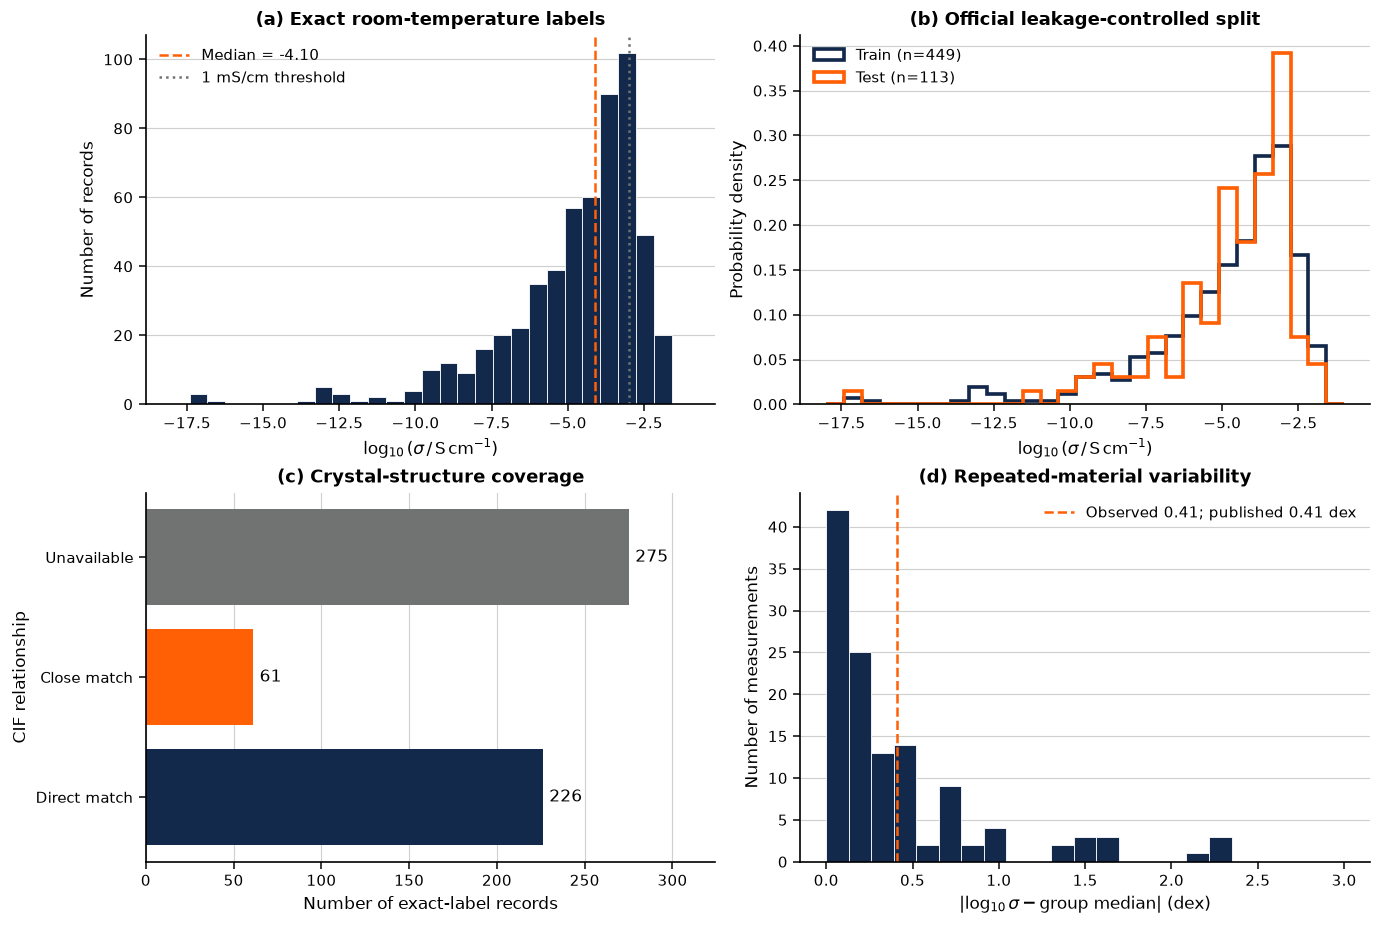

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11.4, 7.6), constrained_layout=True)

# (a) Exact target distribution
target_values = clean_obelix[TARGET_COLUMN]
bins = np.linspace(np.floor(target_values.min()), np.ceil(target_values.max()), 30)
axes[0, 0].hist(target_values, bins=bins, color=ILLINI_BLUE, edgecolor="white", linewidth=0.5)
axes[0, 0].axvline(target_values.median(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Median = {target_values.median():.2f}")
axes[0, 0].axvline(-3, color=ILLINI_STORM, linestyle=":", label="1 mS/cm threshold")
axes[0, 0].set_title("(a) Exact room-temperature labels")
axes[0, 0].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 0].set_ylabel("Number of records")
axes[0, 0].legend(loc="upper left")
finish_axis(axes[0, 0], "y")

# (b) Official split distribution check
for split, color in [("train", ILLINI_BLUE), ("test", ILLINI_ORANGE)]:
    values = clean_obelix.loc[clean_obelix["source_split"].eq(split), TARGET_COLUMN]
    axes[0, 1].hist(values, bins=bins, density=True, histtype="step", linewidth=2.2,
                    color=color, label=f"{split.title()} (n={len(values)})")
axes[0, 1].set_title("(b) Official leakage-controlled split")
axes[0, 1].set_xlabel(r"$\log_{10}(\sigma\,/\,\mathrm{S\,cm^{-1}})$")
axes[0, 1].set_ylabel("Probability density")
axes[0, 1].legend(loc="upper left")
finish_axis(axes[0, 1], "y")

# (c) Structure coverage for exact labels
structure_order = ["matched CIF", "close-match CIF", "no CIF"]
structure_counts = clean_obelix["structure_match"].value_counts().reindex(structure_order)
bars = axes[1, 0].barh(
    ["Direct match", "Close match", "Unavailable"], structure_counts,
    color=[ILLINI_BLUE, ILLINI_ORANGE, ILLINI_STORM],
)
axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_xlim(0, structure_counts.max() * 1.18)
axes[1, 0].set_title("(c) Crystal-structure coverage")
axes[1, 0].set_xlabel("Number of exact-label records")
axes[1, 0].set_ylabel("CIF relationship")
finish_axis(axes[1, 0], "x")

# (d) Experimental repeatability
repeat_bins = np.linspace(0, max(3.0, repeat_abs_deviation.max()), 24)
axes[1, 1].hist(repeat_abs_deviation, bins=repeat_bins, color=ILLINI_BLUE,
                edgecolor="white", linewidth=0.5)
axes[1, 1].axvline(repeat_abs_deviation.mean(), color=ILLINI_ORANGE, linestyle="--",
                   label=f"Observed {repeat_abs_deviation.mean():.2f}; published 0.41 dex")
axes[1, 1].set_title("(d) Repeated-material variability")
axes[1, 1].set_xlabel(r"$|\log_{10}\sigma-\mathrm{group\ median}|$ (dex)")
axes[1, 1].set_ylabel("Number of measurements")
axes[1, 1].legend(loc="upper right")
finish_axis(axes[1, 1], "y")

save_report_figure(fig, "figure_02_obelix_data_audit.png")
plt.show()


**Figure 2.** OBELiX ingestion and quality audit. (a) Distribution of 562 exact experimental room-temperature conductivity labels; the gray reference denotes the commonly used 1 mS/cm fast-conductor threshold. (b) The authors' official train (449) and test (113) subsets retain similar target distributions while preventing shared-composition or shared-publication leakage. (c) Only 287 exact-label entries have a CIF, including 61 close matches. (d) After canonicalizing equivalent formula strings, the current source snapshot contains 123 exact measurements in 48 repeated material groups; their mean absolute deviation from the group median is 0.41 dex, consistent with the published experimental floor.


## 9. Identifiability gate for the physics-informed model

OBELiX provides one nominal room-temperature target per record. At a single temperature $T_0$,

$$
y(T_0)=\log_{10}\sigma_0-\frac{E_a}{k_{\mathrm B}T_0\ln 10},
$$

so infinitely many $(\sigma_0,E_a)$ pairs produce the same $y(T_0)$. Separate activation-energy and prefactor heads are therefore **not identifiable from OBELiX alone**. Fitting them now would add physical-looking parameters without experimental support.

The defensible sequence is:

1. Predict $\log_{10}\sigma_{\mathrm{RT}}$ with a composition MLP and transfer-learned crystal GNN.
2. Calibrate uncertainty against the held-out OBELiX test set and the repeated-measurement noise scale.
3. Add multi-temperature conductivity series with material identities and measurement conditions.
4. Only then fit the Arrhenius layer and test whether its constraints improve extrapolation.


In [10]:
MODEL_READINESS = pd.DataFrame([
    {
        "model stage": "Composition-only MLP",
        "usable exact labels": len(clean_obelix),
        "status": "ready for grouped baseline",
        "decision": "train first",
    },
    {
        "model stage": "Room-temperature crystal GNN",
        "usable exact labels": int(clean_obelix["structure_match"].ne("no CIF").sum()),
        "status": "small-data transfer learning only",
        "decision": "freeze encoder initially",
    },
    {
        "model stage": "Direct-match crystal GNN sensitivity check",
        "usable exact labels": int(clean_obelix["structure_match"].eq("matched CIF").sum()),
        "status": "higher-confidence structure subset",
        "decision": "compare with all-CIF subset",
    },
    {
        "model stage": "Arrhenius PI-ACGNN",
        "usable exact labels": 0,
        "status": "not identifiable from room-temperature-only data",
        "decision": "wait for multi-temperature labels",
    },
])
display(MODEL_READINESS)


,model stage,usable exact labels,status,decision
0,Composition-only MLP,562,ready for grouped baseline,train first
1,Room-temperature crystal GNN,287,small-data transfer learning only,freeze encoder initially
2,Direct-match crystal GNN sensitivity check,226,higher-confidence structure subset,compare with all-CIF subset
3,Arrhenius PI-ACGNN,0,not identifiable from room-temperature-only data,wait for multi-temperature labels


## 10. Next modeling milestone

The next implementation step is the composition-only MLP baseline on the official OBELiX split, using linked material/DOI groups for cross-validation within the training set. It should report MAE, RMSE, $R^2$, group-bootstrap confidence intervals, and uncertainty calibration. Only after that baseline is frozen should the project extract crystal embeddings and evaluate whether transfer learning adds value on the smaller CIF subset.

For later multiscale simulations, candidate selection should combine high predicted conductivity, calibrated uncertainty, structure confidence, chemical diversity, and practical suitability for DFT/MD—not conductivity rank alone.
